Dataset Shape: (253, 4096)
Labels: (array([0, 1]), array([ 98, 155]))

Accuracy: 0.8823529411764706

Classification Report:
              precision    recall  f1-score   support

    No Tumor       0.89      0.80      0.84        20
       Tumor       0.88      0.94      0.91        31

    accuracy                           0.88        51
   macro avg       0.88      0.87      0.87        51
weighted avg       0.88      0.88      0.88        51


Confusion Matrix:
[[16  4]
 [ 2 29]]


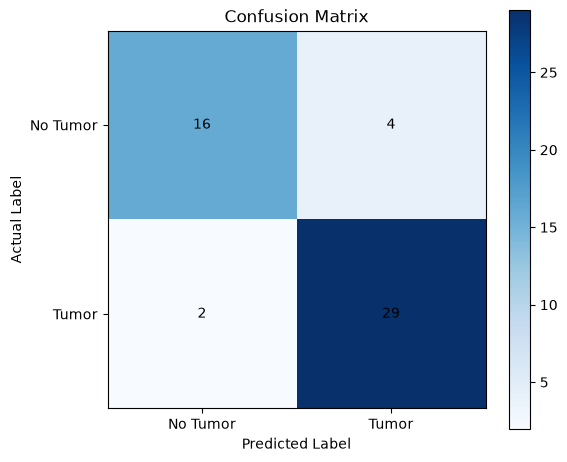

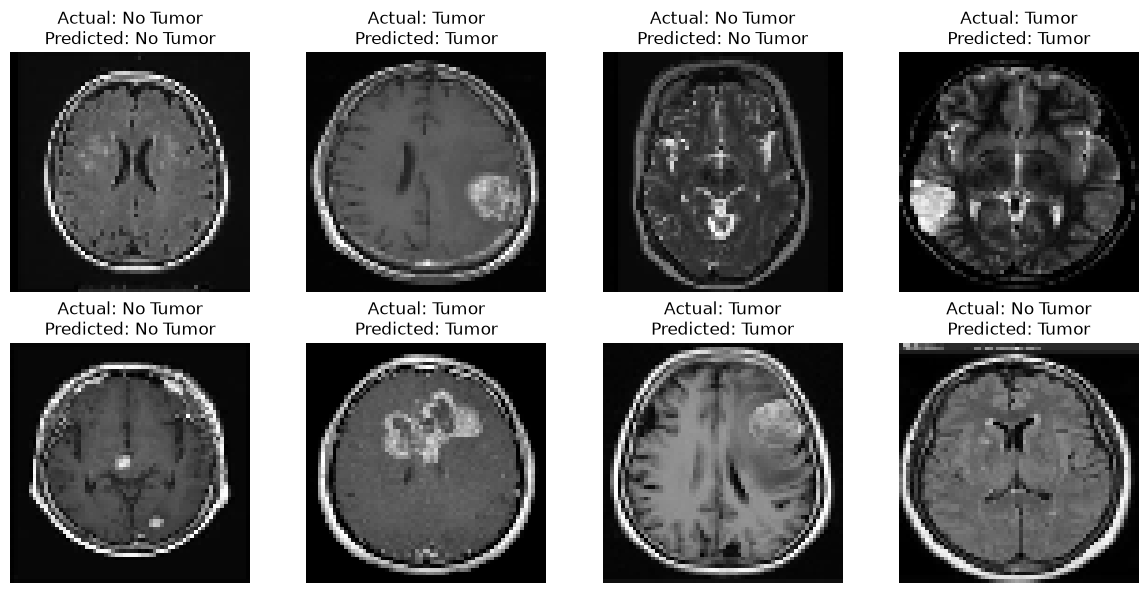

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

path = r"brain_tumor_dataset"  

images = []
labels = []
image_paths = []

for folder, label in [("yes", 1), ("no", 0)]:
    folder_path = os.path.join(path, folder)

    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path, file)
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        if image is not None:
            image = cv2.resize(image, (64, 64))
            images.append(image.flatten())
            labels.append(label)
            image_paths.append(image_path)

X = np.array(images)
y = np.array(labels)
image_paths = np.array(image_paths)

print("Dataset Shape:", X.shape)
print("Labels:", np.unique(y, return_counts=True))

X_train, X_test, y_train, y_test, train_paths, test_paths = train_test_split(
    X, y, image_paths, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SVC(kernel="rbf", C=10, gamma="scale")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=["No Tumor", "Tumor"], zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.colorbar()
plt.xticks([0, 1], ["No Tumor", "Tumor"])
plt.yticks([0, 1], ["No Tumor", "Tumor"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="black")

plt.tight_layout()
plt.show()

sample_count = min(8, len(X_test))
plt.figure(figsize=(12, 6))

for i in range(sample_count):
    image = cv2.imread(test_paths[i], cv2.IMREAD_GRAYSCALE)
    image = cv2.resize(image, (64, 64))

    plt.subplot(2, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(
        f"Actual: {'Tumor' if y_test[i] == 1 else 'No Tumor'}\n"
        f"Predicted: {'Tumor' if y_pred[i] == 1 else 'No Tumor'}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()
